# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = cfg(PIPELINE_CONFIG, "si.min_avg_amr_publications_per_year")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

# Driver plots and display controls.
CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "si.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "si.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "si.driver_lookback_years")
MAX_DRIVER_PLOTS = cfg(PIPELINE_CONFIG, "si.max_driver_plots")
MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 2,938
yearly_screened unique pathogens: 43
yearly_screened unique antibiotics: 128
yearly_screened year range: 2000 - 2010
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 25,900


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 2,938
model pathogen-antibiotic rows: 960
model antibiotic values: 128
model antibiotic background rows: 5,319
model unified decision rows: 25,900


,pathogen,antibiotic,year,count,pmids
0,Acinetobacter baumannii,Amikacin,2003,2,"[12872781, 14748260]"
1,Acinetobacter baumannii,Amikacin,2005,2,"[16103700, 16258323]"
2,Acinetobacter baumannii,Amikacin,2006,2,"[16597632, 16776825]"
3,Acinetobacter baumannii,Amikacin,2008,2,"[18261233, 18792817]"
4,Acinetobacter baumannii,Amoxicillin,2004,1,[15004037]
5,Acinetobacter baumannii,Ampicillin,2000,1,[10705052]
6,Acinetobacter baumannii,Ampicillin/sulbactam,2003,3,"[12848733, 12872781, 14748260]"
7,Acinetobacter baumannii,Ampicillin/sulbactam,2004,1,[15004037]
8,Acinetobacter baumannii,Ampicillin/sulbactam,2005,2,"[16103700, 16258323]"
9,Acinetobacter baumannii,Ampicillin/sulbactam,2007,1,[17722953]


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 11 / 960 pairs with >= 4 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 43
model input after publication filter pathogens: 5
Pathogens present in model input before publication filter but absent from model input after publication filter: 38
Acinetobacter baumannii, Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Campylobacter jejuni, Chlamydia pneumoniae, Chlamydia trachomatis, Clostridioides difficile, Clostridium perfringens, Cutibacterium acnes, Enterococcus faecalis, Enterococcus faecium, Francisella tularensis, Haemophilus influenzae, Klebsiella pneumoniae, Listeria monocytogenes, Moraxella catarrhalis, Mycobacterium abscessus, Mycobacterium avium, Mycobacterium leprae, Mycobacterium tuberculosis, Mycoplasmoides pneumoniae, Neisseria gonorrhoeae, Neisseria meningitidis, Porphyromo

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Acinetobacter baumannii,121,161,41,0.0,0.0,0.0,True,False,missing_from_modeled
1,Aggregatibacter actinomycetemcomitans,5,5,4,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bacillus anthracis,20,20,18,0.0,0.0,0.0,True,False,missing_from_modeled
3,Bordetella pertussis,2,2,1,0.0,0.0,0.0,True,False,missing_from_modeled
4,Borrelia burgdorferi,14,14,10,0.0,0.0,0.0,True,False,missing_from_modeled
5,Brucella melitensis,12,12,9,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia cepacia,19,19,12,0.0,0.0,0.0,True,False,missing_from_modeled
7,Burkholderia pseudomallei,17,17,16,0.0,0.0,0.0,True,False,missing_from_modeled
8,Campylobacter jejuni,79,168,26,0.0,0.0,0.0,True,False,missing_from_modeled
9,Chlamydia pneumoniae,7,7,6,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
722,Staphylococcus aureus,Meticillin,340,14.166667
252,Escherichia coli,Ampicillin,191,7.958333
859,Streptococcus pneumoniae,Erythromycin,154,6.416667
278,Escherichia coli,Ciprofloxacin,152,6.333333
322,Escherichia coli,Tetracycline,137,5.708333
382,Helicobacter pylori,Clarithromycin,125,5.208333
388,Helicobacter pylori,Metronidazole,113,4.708333
753,Staphylococcus aureus,Vancomycin,112,4.666667
317,Escherichia coli,Sulfamethoxazole,103,4.291667
611,Salmonella enterica,Ampicillin,103,4.291667


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 97
SI pairs: 11
SI pathogens: 5
filtered model input pathogens: 5
yearly SI output pathogens: 5


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Escherichia coli,Ampicillin,2000,11,"[10660502, 10768473, 10792544, 10794949, 10811...",6237,400,1.079181,3.795045,2.603144,1.265578,17.432226,-0.186397
1,Escherichia coli,Ampicillin,2001,11,"[11310799, 11427743, 11442990, 11483011, 11545...",6356,432,1.079181,3.803252,2.636488,1.278637,17.994880,-0.199455
2,Escherichia coli,Ampicillin,2002,18,"[11823193, 11897070, 11977863, 12010552, 12053...",6193,429,1.278754,3.791971,2.633468,1.274927,17.833343,0.003826
3,Escherichia coli,Ampicillin,2003,15,"[12493789, 12562721, 12593930, 12615864, 12688...",6326,450,1.204120,3.801198,2.654177,1.284028,18.232147,-0.079908
4,Escherichia coli,Ampicillin,2004,25,"[14718005, 14746546, 15023432, 15031799, 15055...",6809,475,1.414973,3.833147,2.677607,1.299482,18.928826,0.115492
5,Escherichia coli,Ampicillin,2005,27,"[15613004, 15621444, 15673777, 15702791, 15715...",7207,517,1.447158,3.857815,2.714330,1.317611,19.778359,0.129547
6,Escherichia coli,Ampicillin,2006,24,"[16300850, 16330058, 16372265, 16405684, 16545...",7509,465,1.397940,3.875640,2.668386,1.306603,19.258289,0.091337
7,Escherichia coli,Ampicillin,2007,29,"[17011059, 17098382, 17335597, 17353219, 17363...",7684,527,1.477121,3.885644,2.722634,1.327046,20.234688,0.150075
8,Escherichia coli,Ampicillin,2008,31,"[18162377, 18165861, 18227764, 18234027, 18282...",7860,511,1.505150,3.895478,2.709270,1.324958,20.132868,0.180192
9,Escherichia coli,Ciprofloxacin,2000,5,"[10730338, 10837431, 10926444, 11421374, 11798...",6237,602,0.778151,3.795045,2.780317,1.175940,13.994760,-0.397788


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/11] ranking Escherichia coli vs Ampicillin
[2/11] ranking Escherichia coli vs Ciprofloxacin
[3/11] ranking Escherichia coli vs Sulfamethoxazole
[4/11] ranking Escherichia coli vs Sulfamethoxazole/trimethoprim
[5/11] ranking Escherichia coli vs Tetracycline
[6/11] ranking Helicobacter pylori vs Clarithromycin
[7/11] ranking Helicobacter pylori vs Metronidazole
[8/11] ranking Salmonella enterica vs Ampicillin
[9/11] ranking Staphylococcus aureus vs Meticillin
[10/11] ranking Staphylococcus aureus vs Vancomycin
[11/11] ranking Streptococcus pneumoniae vs Erythromycin


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Salmonella enterica,Ampicillin,0.596300,0.642095,3639.337997,16581.392256,0.011331,NaN
1,Escherichia coli,Tetracycline,0.548640,0.598569,3066.044747,12058.185073,0.006256,NaN
2,Escherichia coli,Sulfamethoxazole,0.408240,0.471709,1485.022623,5114.894146,0.009186,NaN
3,Escherichia coli,Ciprofloxacin,0.239410,0.308371,419.584054,917.710799,0.001346,NaN
4,Escherichia coli,Sulfamethoxazole/trimethoprim,0.113995,0.168158,103.205472,177.191101,0.008099,NaN
5,Escherichia coli,Ampicillin,0.110778,0.158473,139.577949,216.318311,0.002324,NaN


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_target_pair_supported_share
0,Salmonella enterica,Ampicillin,0.596300,0.642095,3639.337997,16581.392256,0,0,None,None,0.0,0.0
1,Escherichia coli,Tetracycline,0.548640,0.598569,3066.044747,12058.185073,0,0,None,None,0.0,0.0
2,Escherichia coli,Sulfamethoxazole,0.408240,0.471709,1485.022623,5114.894146,0,0,None,None,0.0,0.0
3,Escherichia coli,Ciprofloxacin,0.239410,0.308371,419.584054,917.710799,0,0,None,None,0.0,0.0
4,Escherichia coli,Sulfamethoxazole/trimethoprim,0.113995,0.168158,103.205472,177.191101,0,0,None,None,0.0,0.0
5,Escherichia coli,Ampicillin,0.110778,0.158473,139.577949,216.318311,0,0,None,None,0.0,0.0


## Plot Category Driver Curves


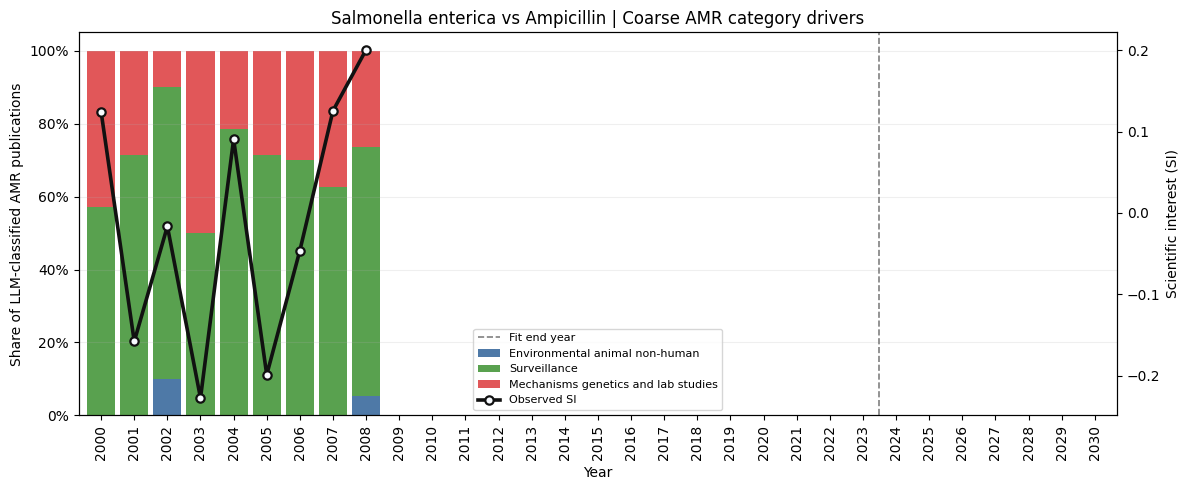

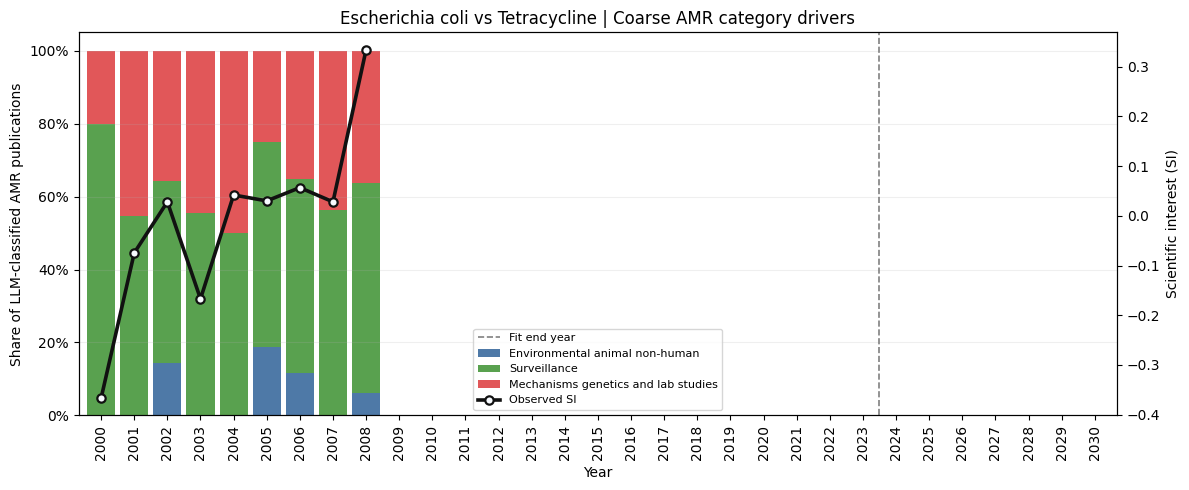

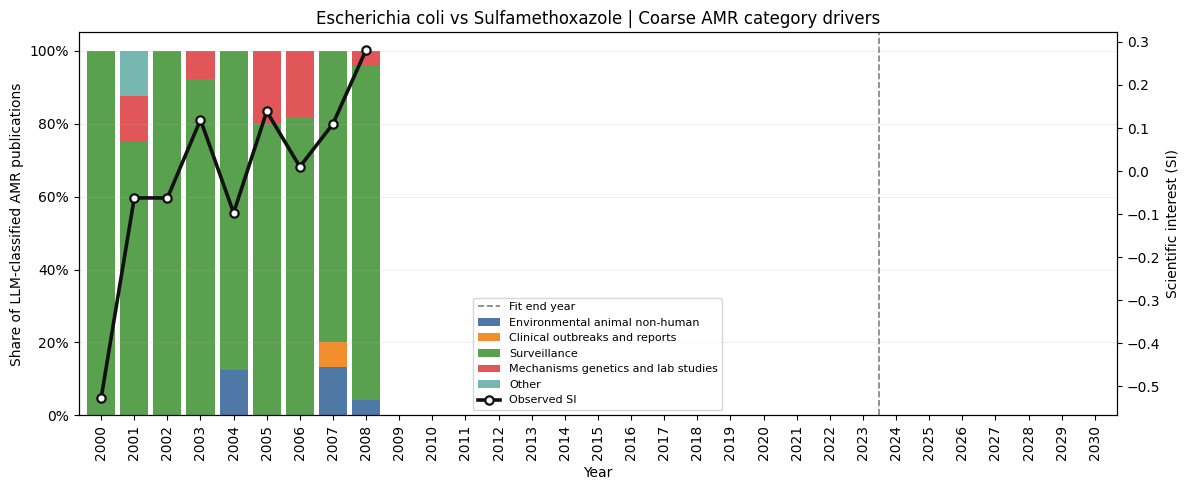

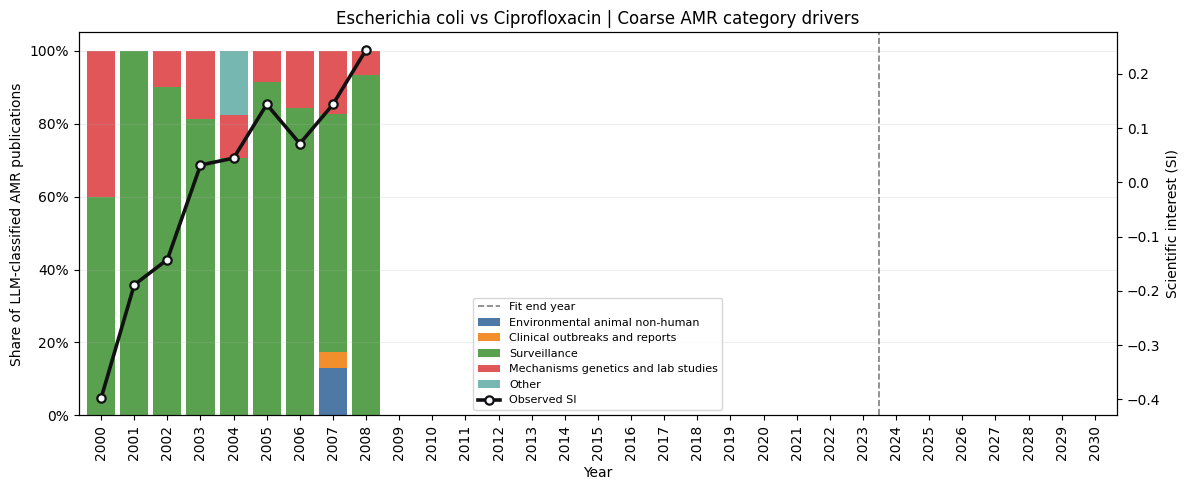

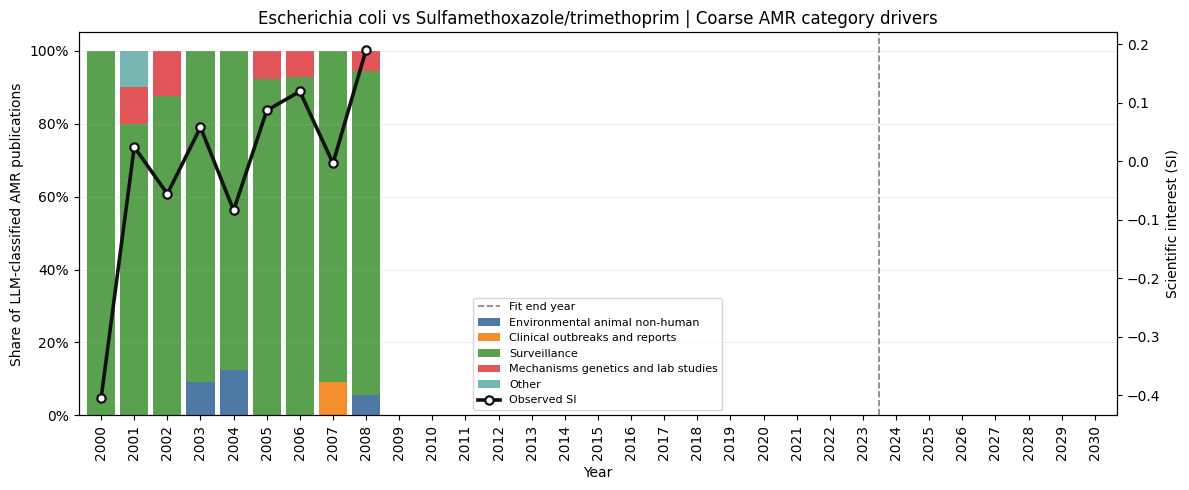

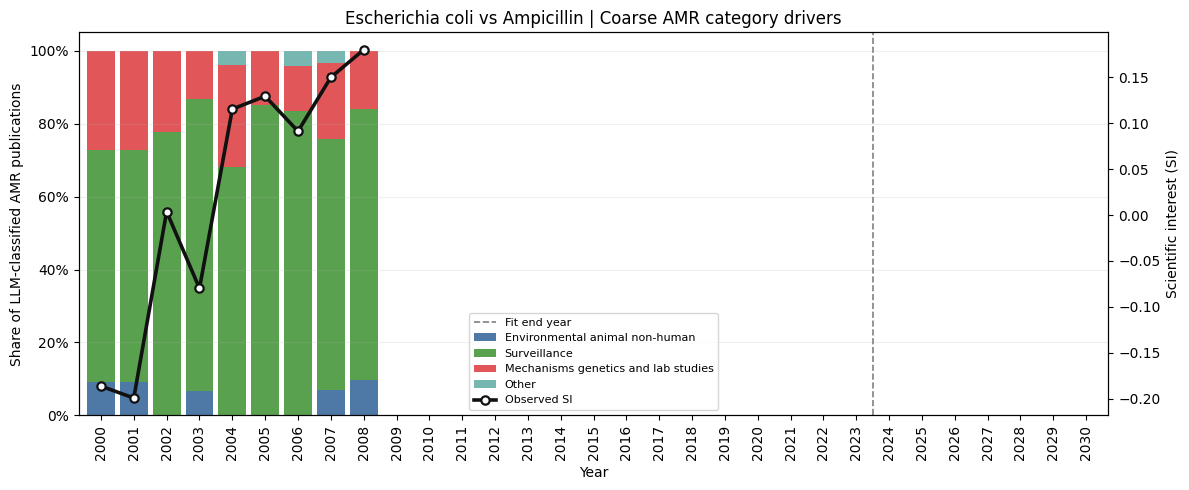

Saved 6 coarse category driver plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 6 category driver plots inline.


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


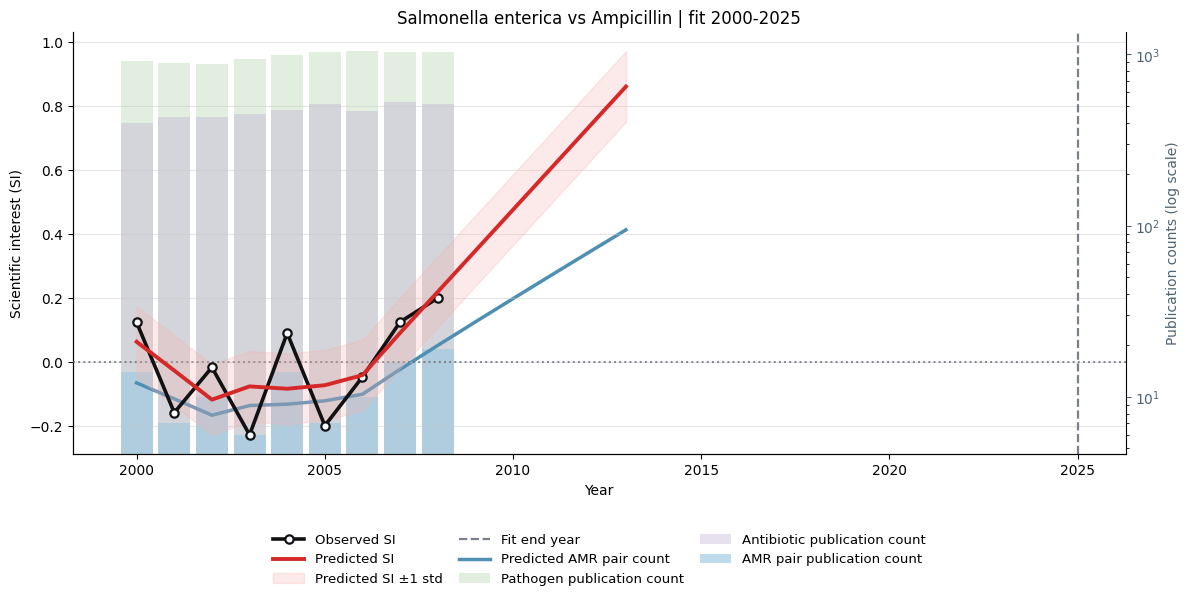

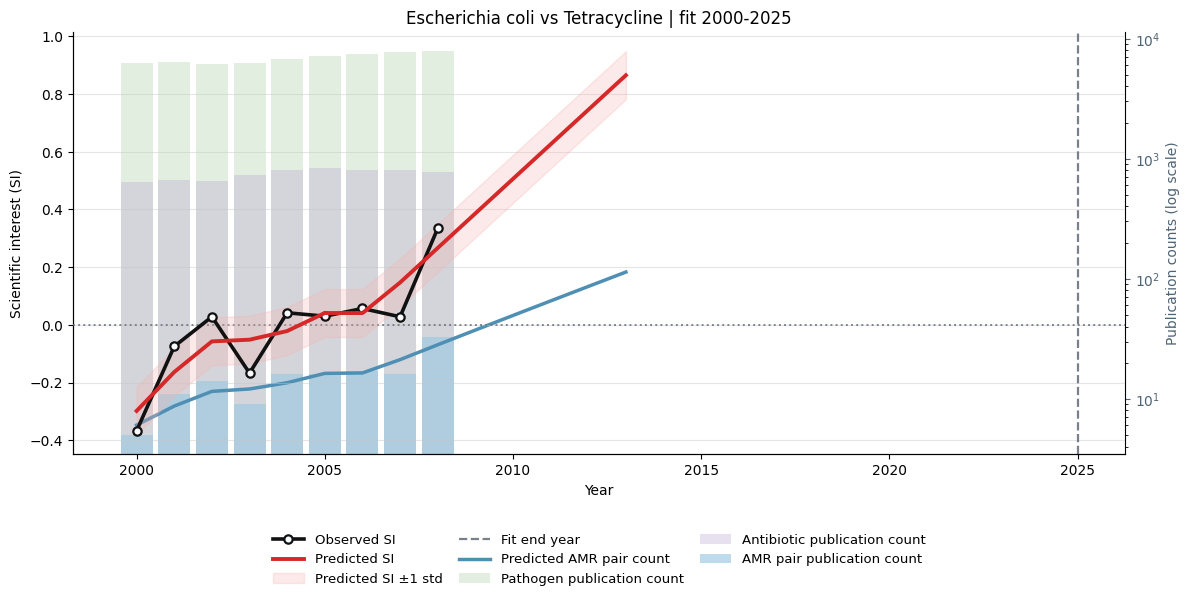

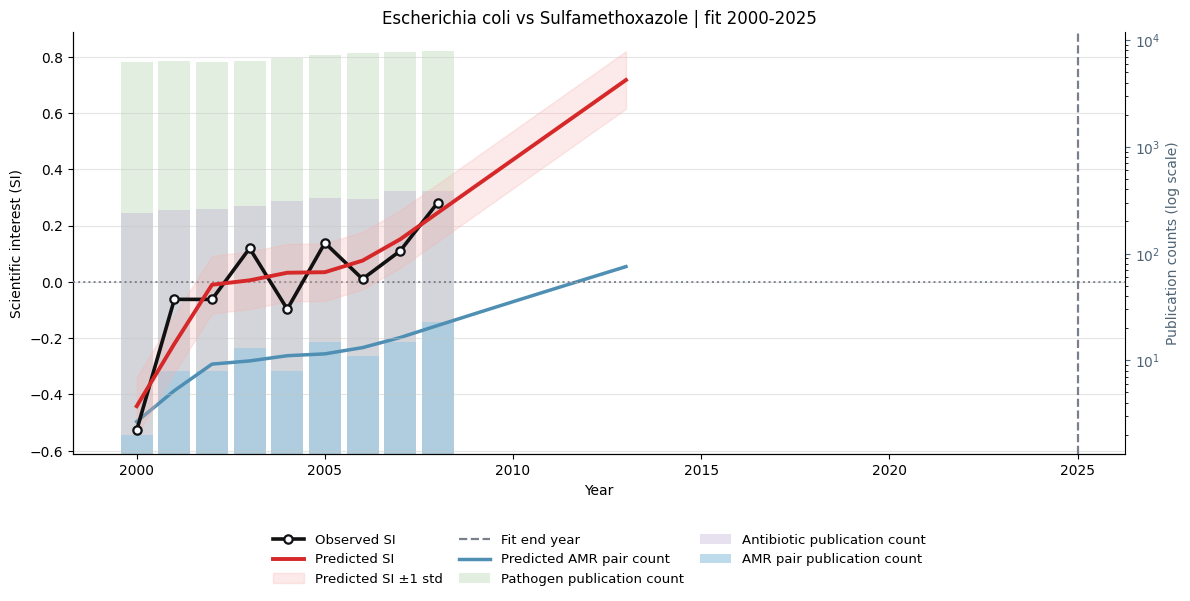

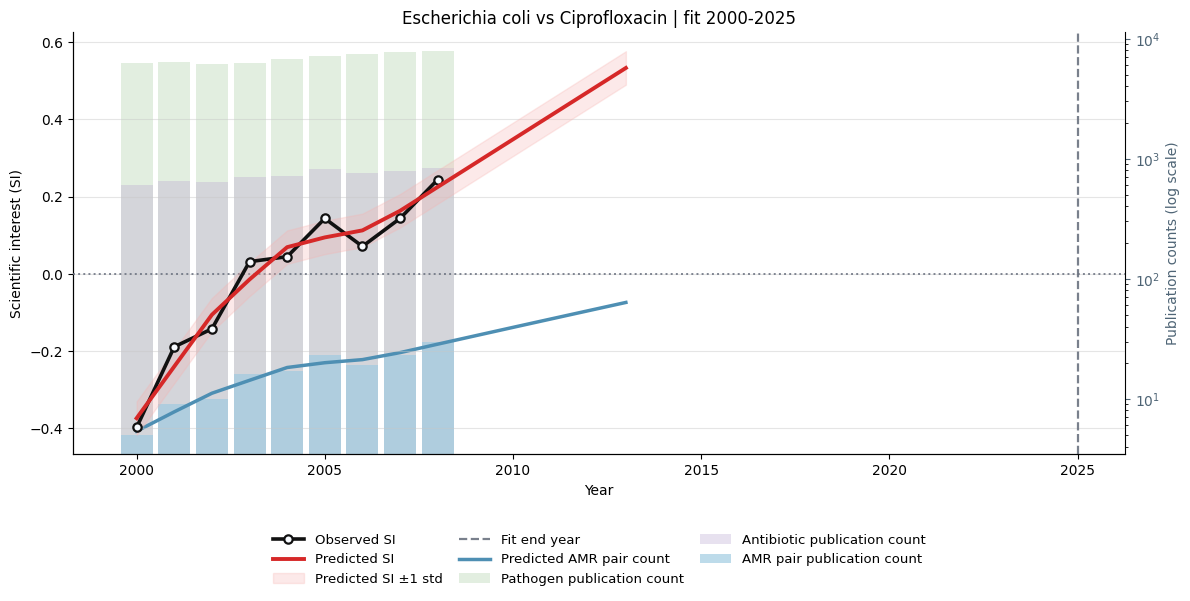

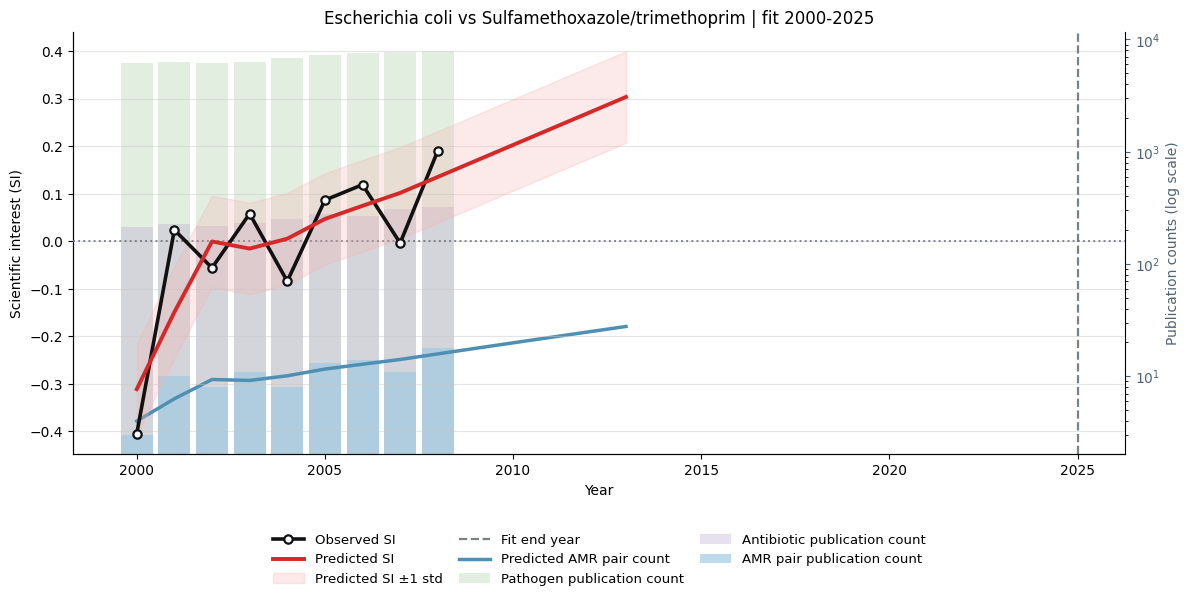

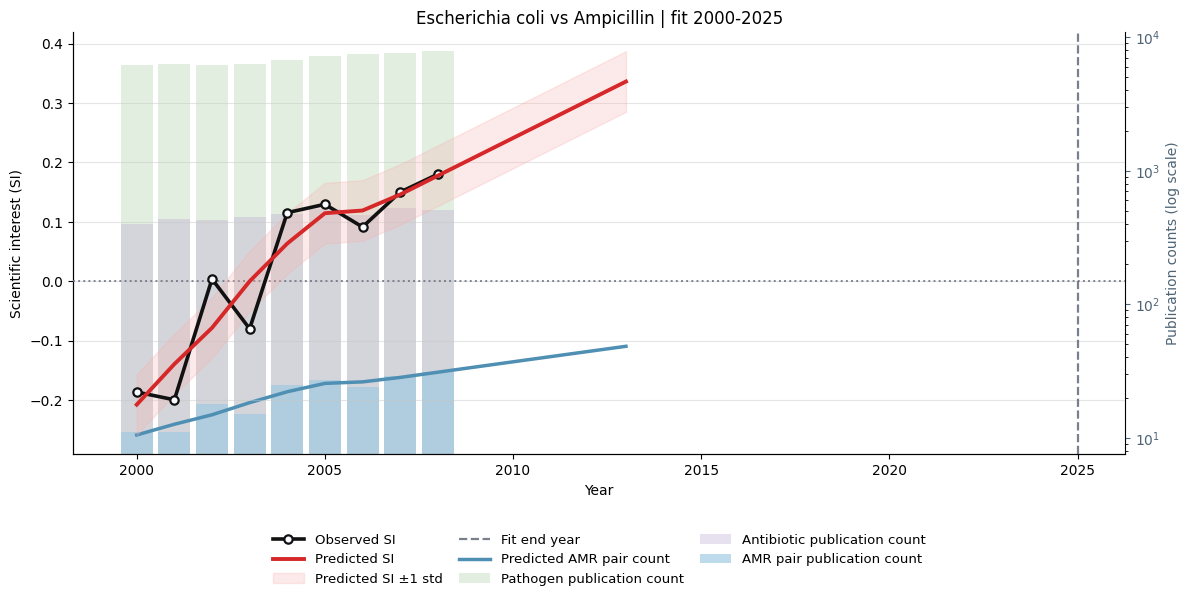

Saved 6 plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 6 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [12]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 5 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Helicobacter pylori,Metronidazole,2025,2030,-4.384508,-5.533088,-1.148580,0.000000,0.0,0.006038,NaN
1,Helicobacter pylori,Clarithromycin,2025,2030,-2.107360,-2.687518,-0.580158,0.000000,0.0,0.006258,NaN
2,Staphylococcus aureus,Meticillin,2025,2030,-1.881494,-2.442382,-0.560888,0.613003,0.0,0.001471,NaN
3,Streptococcus pneumoniae,Erythromycin,2025,2030,-1.722401,-2.180570,-0.458168,0.000000,0.0,0.002861,NaN
4,Staphylococcus aureus,Vancomycin,2025,2030,-1.476869,-1.879381,-0.402512,0.000000,0.0,0.003993,NaN


### Most Convex and Concave Smoothed SI Curves


In [13]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 3 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 8 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean
0,Helicobacter pylori,Metronidazole,2000,2006,2025,2013,0.207231,-0.035550,-1.627916,1.835147,-0.674793,0.674793,-0.012743,0.993870,-1.148580,0.006038
1,Staphylococcus aureus,Meticillin,2000,2008,2025,2015,0.006457,0.104096,-0.759718,0.766175,-0.480726,0.480726,-0.007448,0.961594,-0.560888,0.001471
2,Helicobacter pylori,Clarithromycin,2000,2006,2025,2013,0.067655,0.081739,-0.714980,0.782635,-0.405402,0.405402,-0.007494,0.963746,-0.580158,0.006258
3,Streptococcus pneumoniae,Erythromycin,2000,2006,2025,2012,-0.001732,0.018638,-0.531164,0.529432,-0.285086,0.285086,-0.008358,0.955563,-0.458168,0.002861
4,Staphylococcus aureus,Vancomycin,2000,2006,2025,2012,0.015620,0.052675,-0.430339,0.445959,-0.260035,0.260035,-0.005857,0.909835,-0.402512,0.003993
5,Escherichia coli,Sulfamethoxazole/trimethoprim,2000,2006,2025,2013,-0.311088,0.074674,0.303626,0.614714,-0.078405,0.078405,-0.001865,0.937052,0.168158,0.008099
6,Escherichia coli,Ampicillin,2000,2006,2025,2013,-0.207570,0.119094,0.336156,0.543726,-0.054801,0.054801,-0.001921,0.987493,0.158473,0.002324
7,Escherichia coli,Ciprofloxacin,2000,2006,2025,2013,-0.373905,0.112688,0.533527,0.907432,-0.032877,0.032877,-0.001777,0.978669,0.308371,0.001346


### Plots for Additional SI Shape Screens


In [14]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


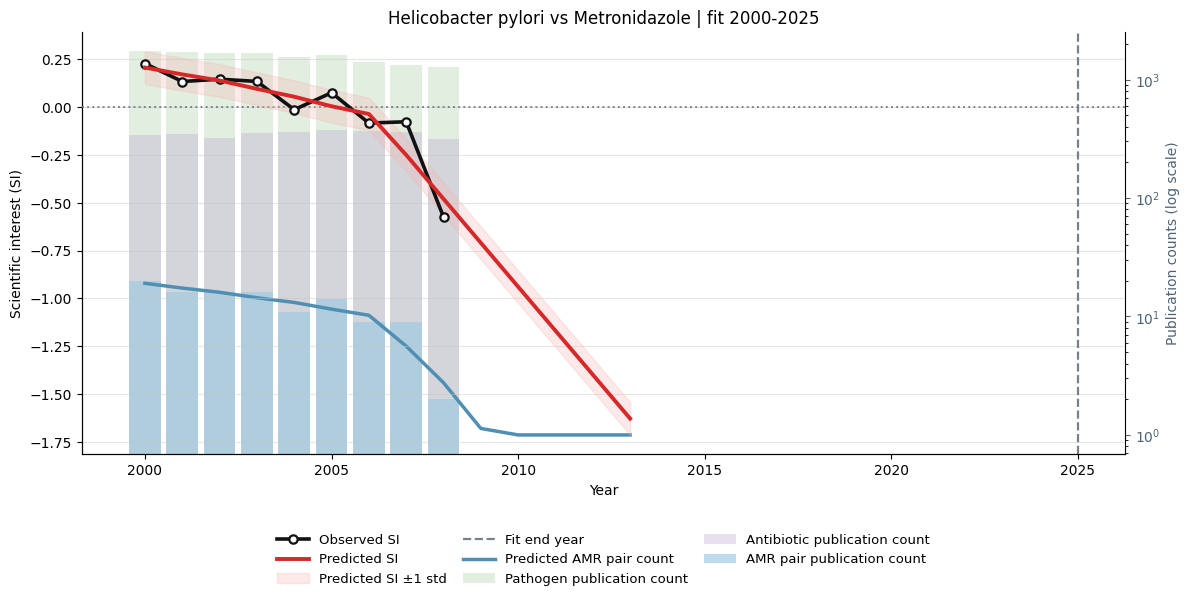

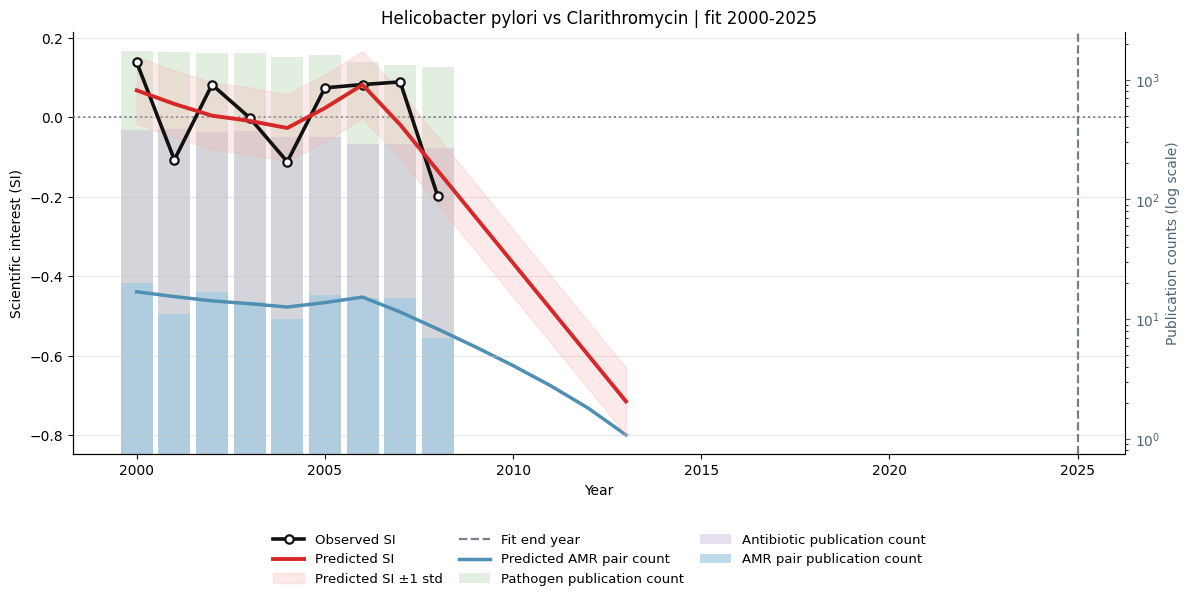

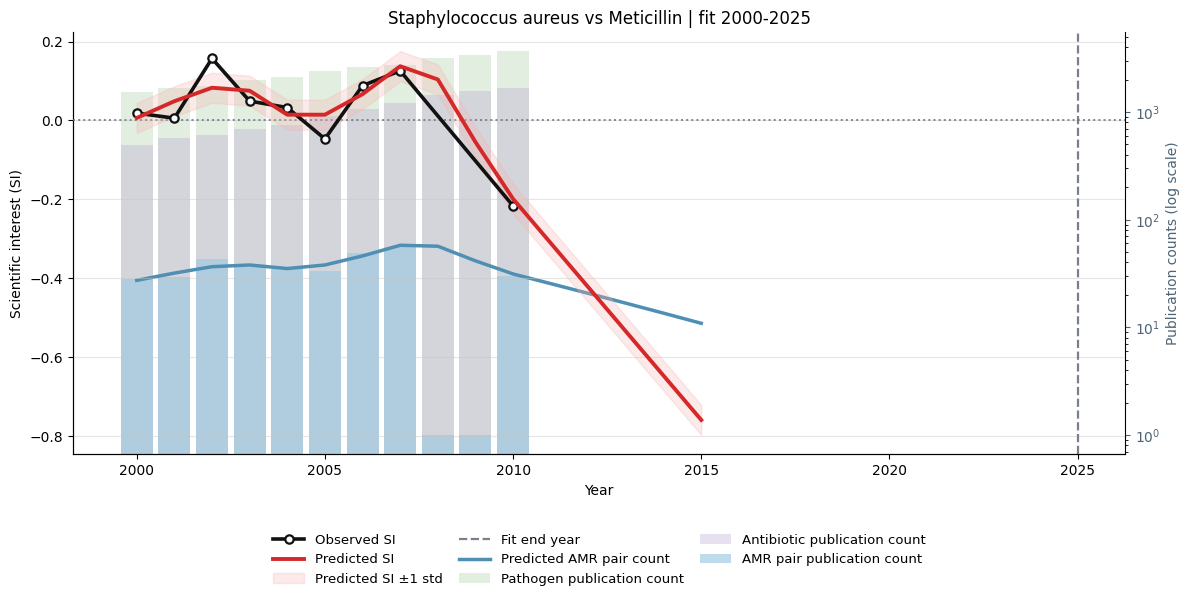

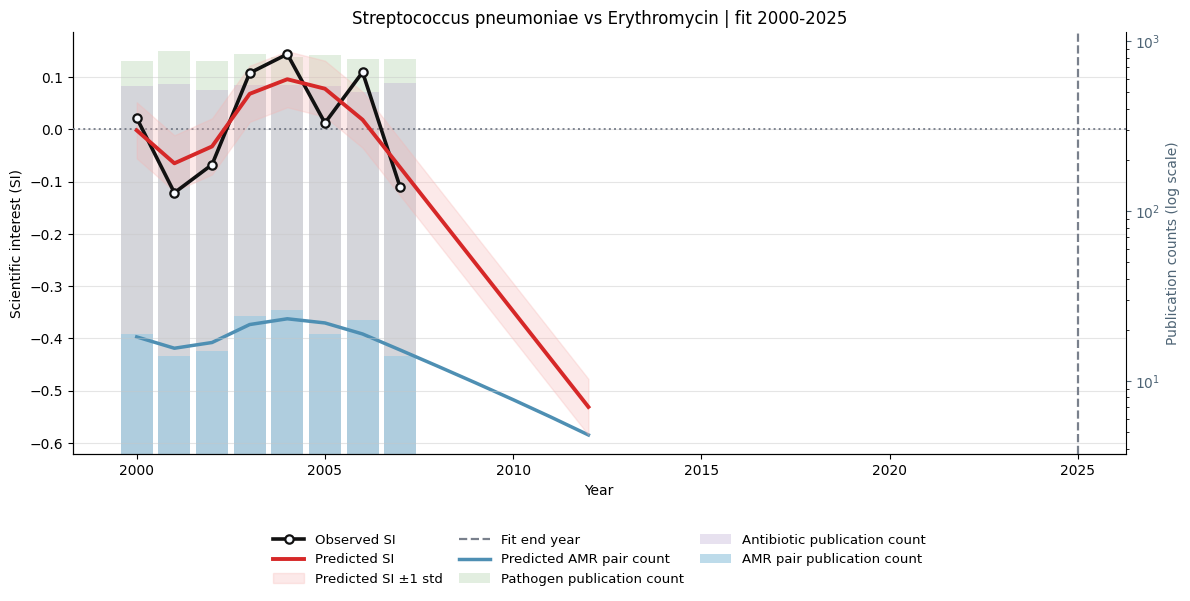

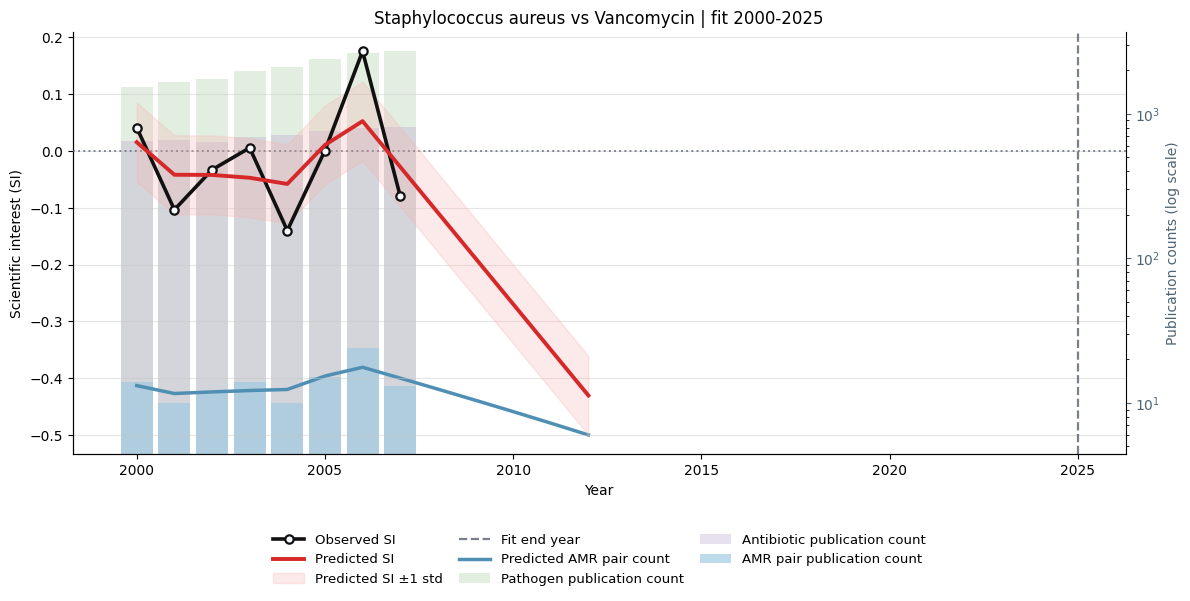

Saved 5 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots


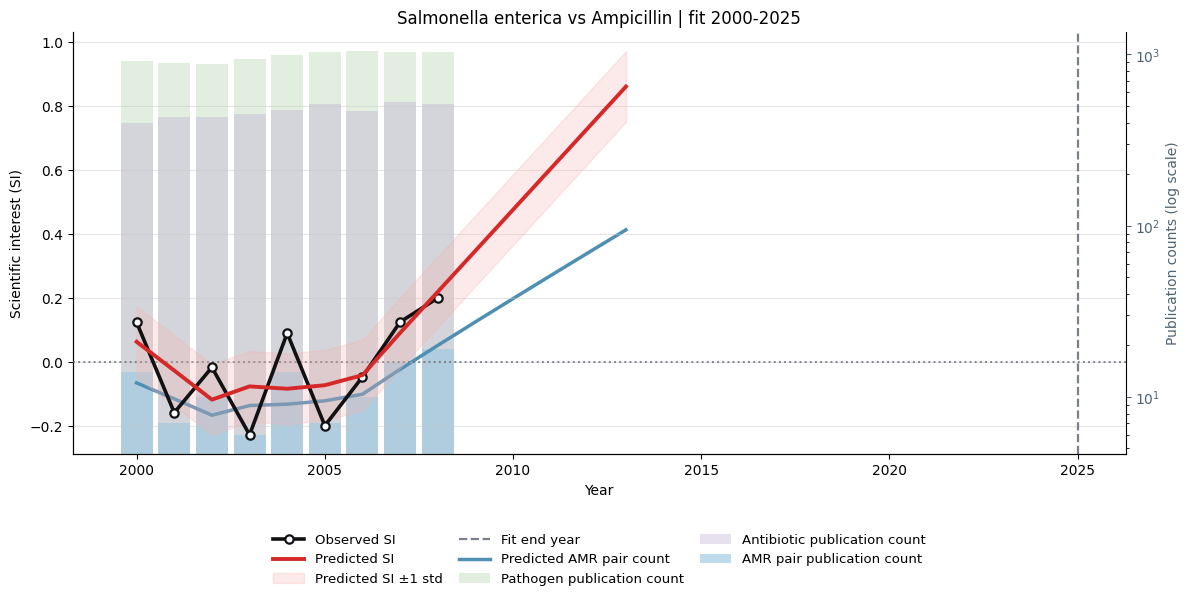

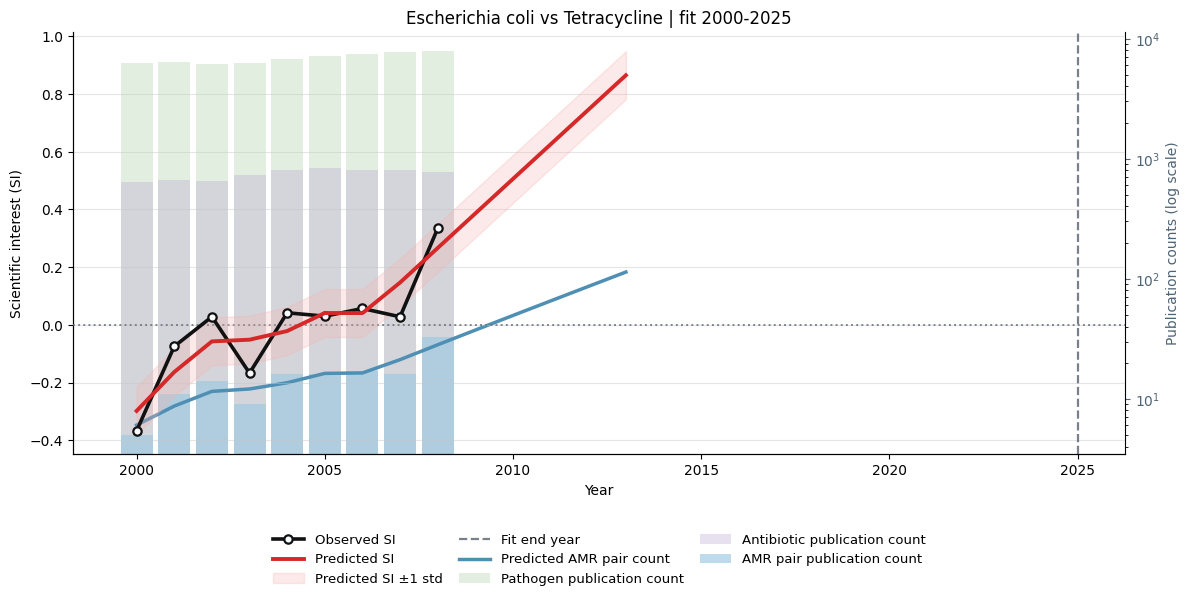

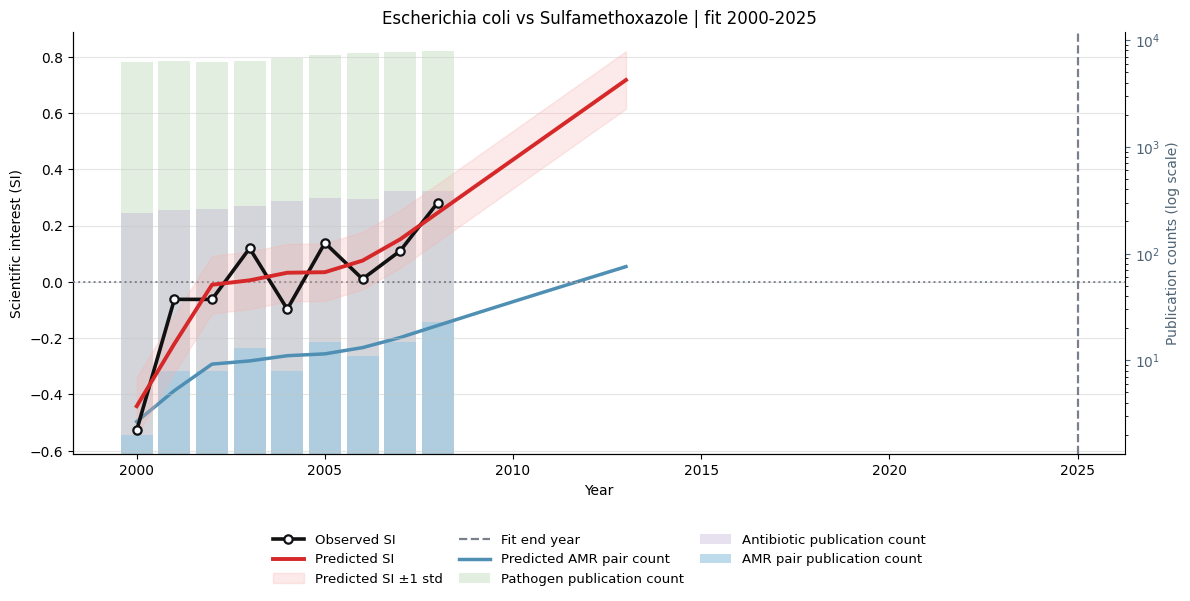

Saved 3 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots


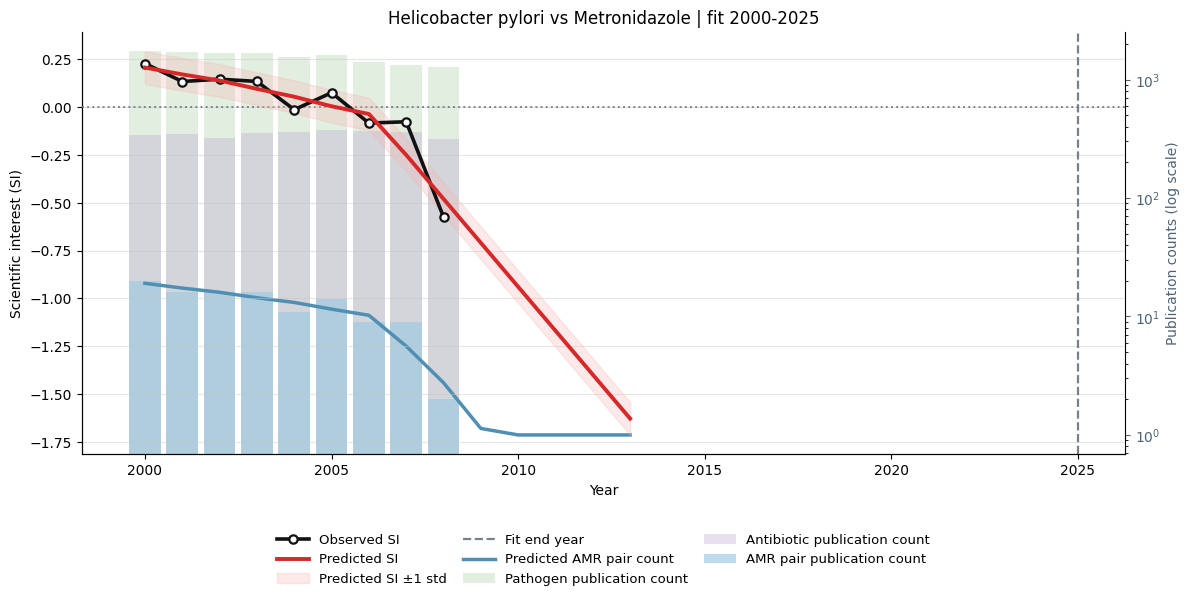

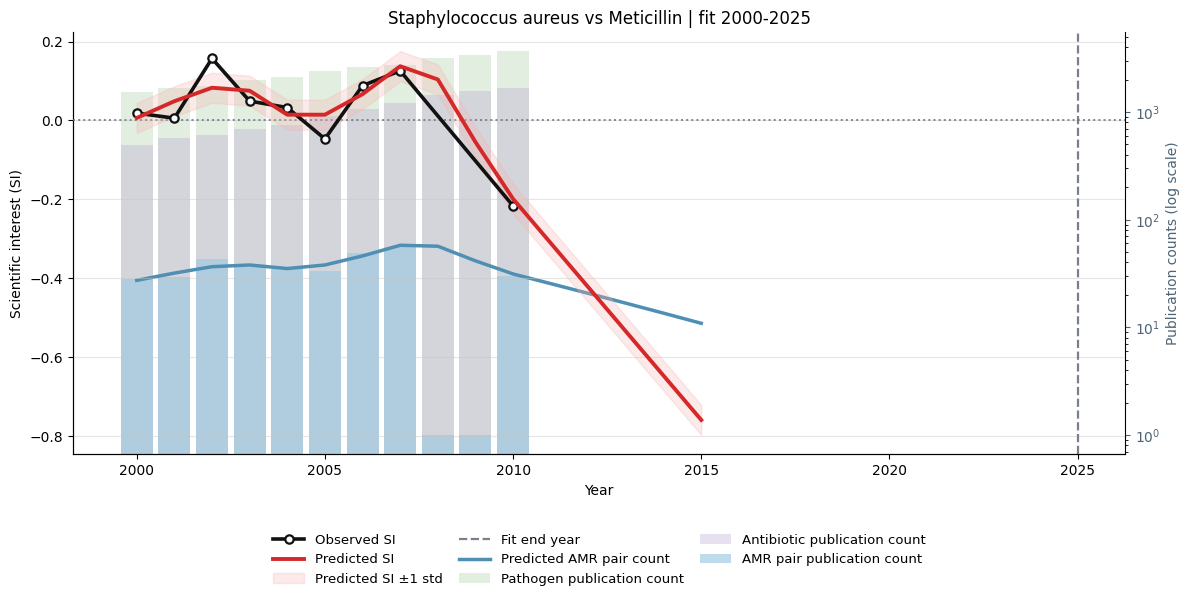

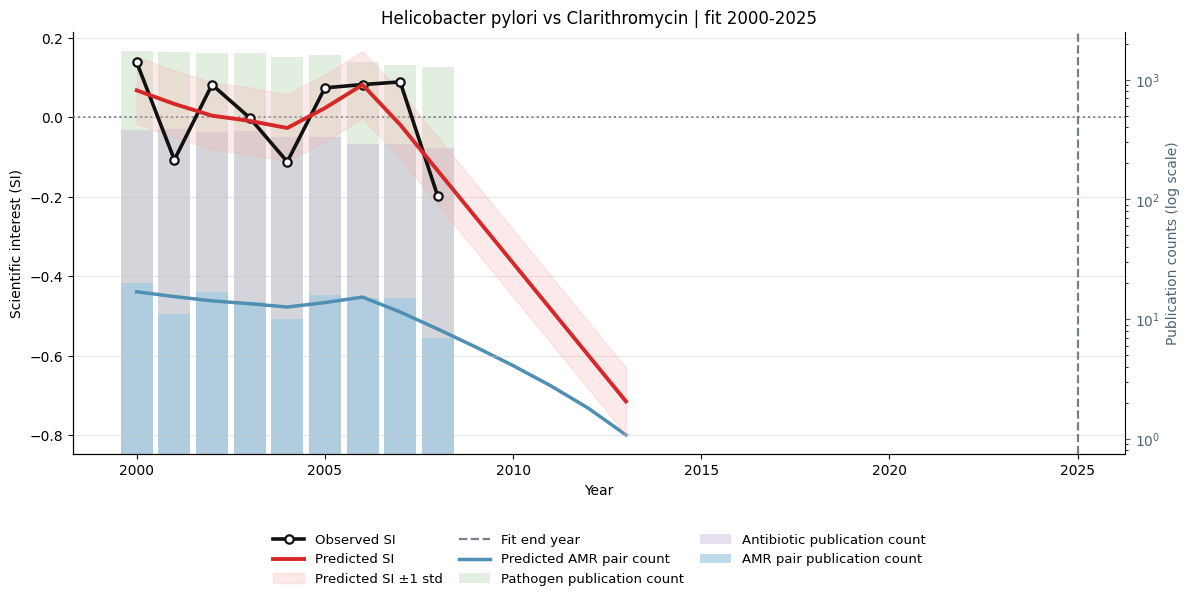

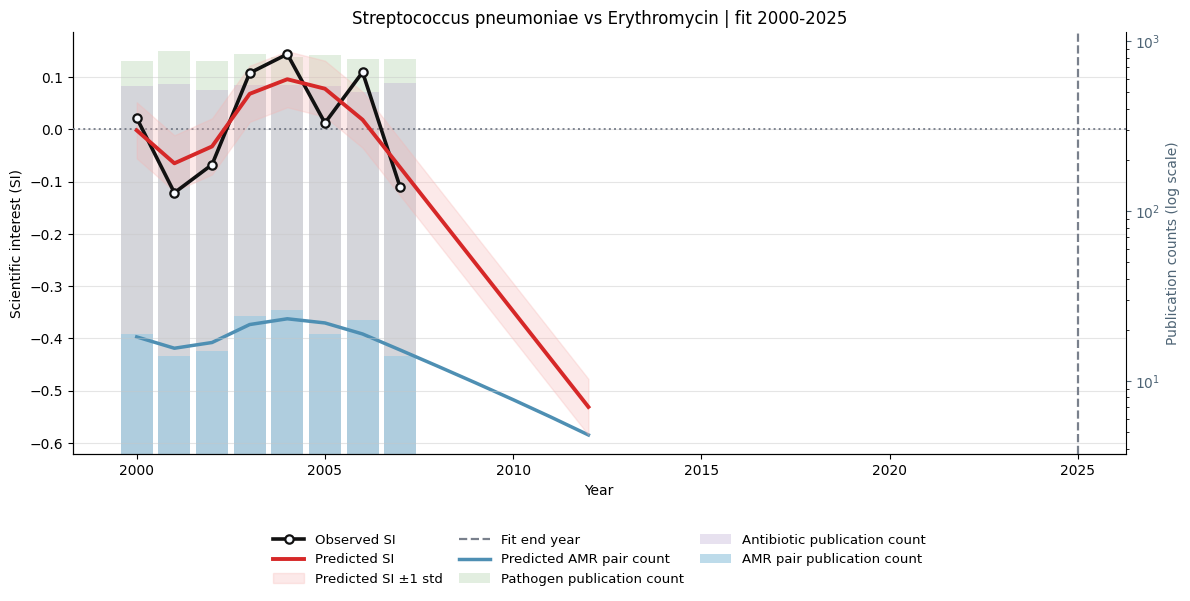

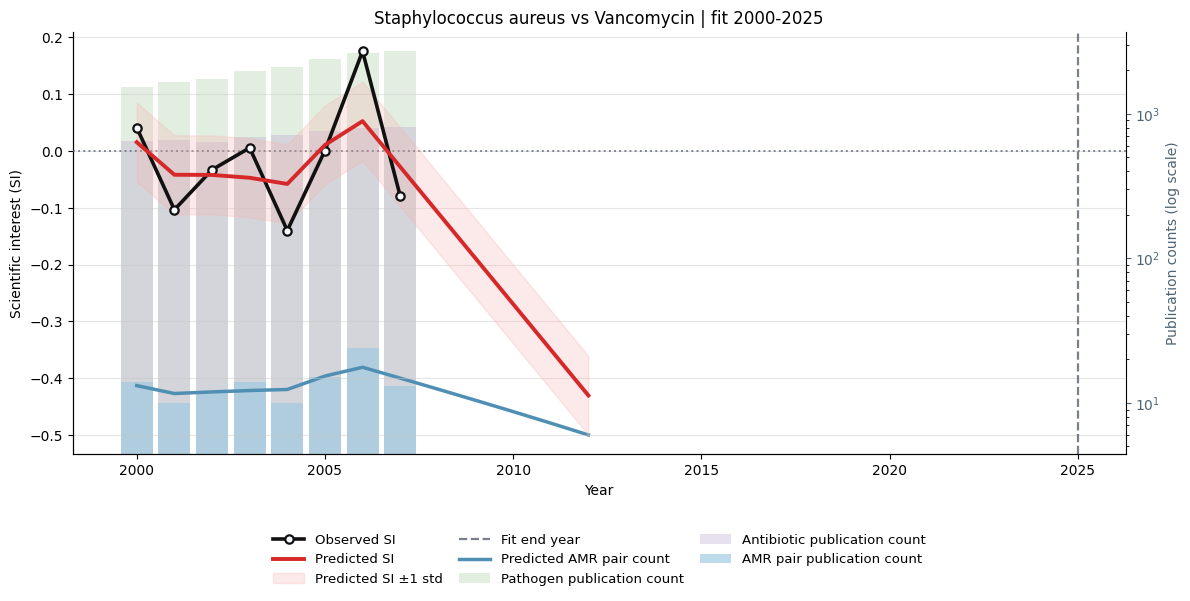

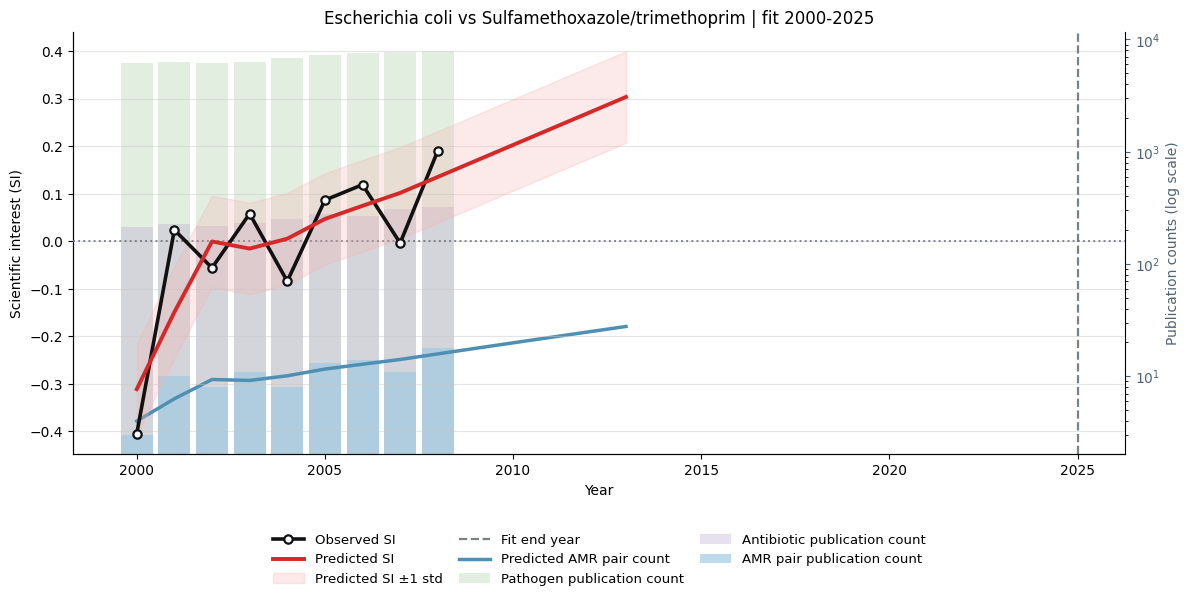

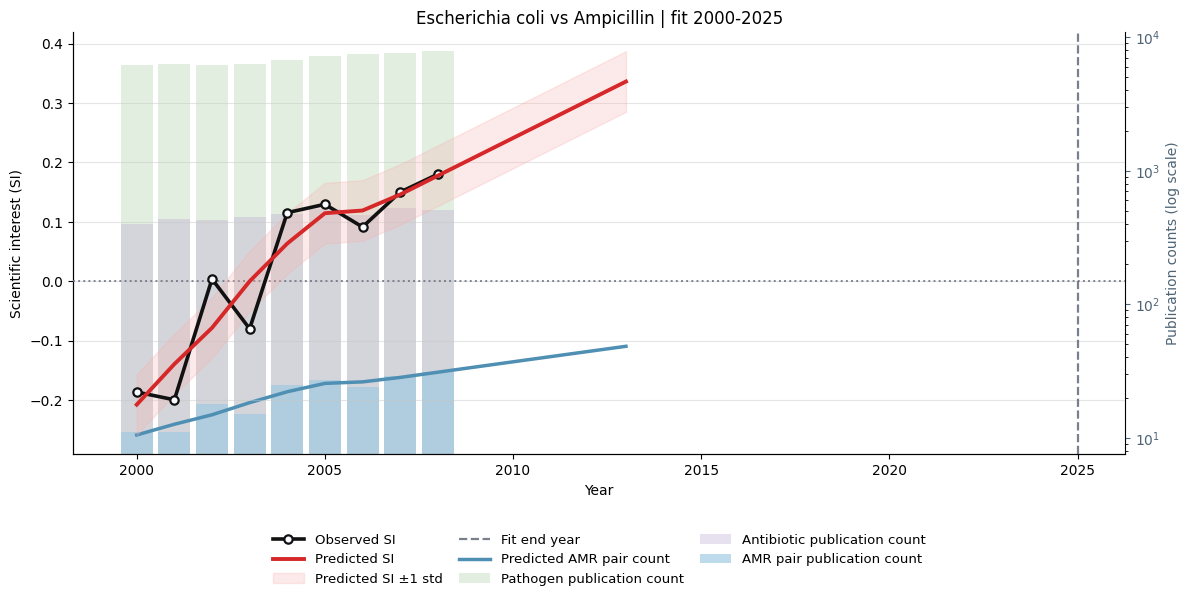

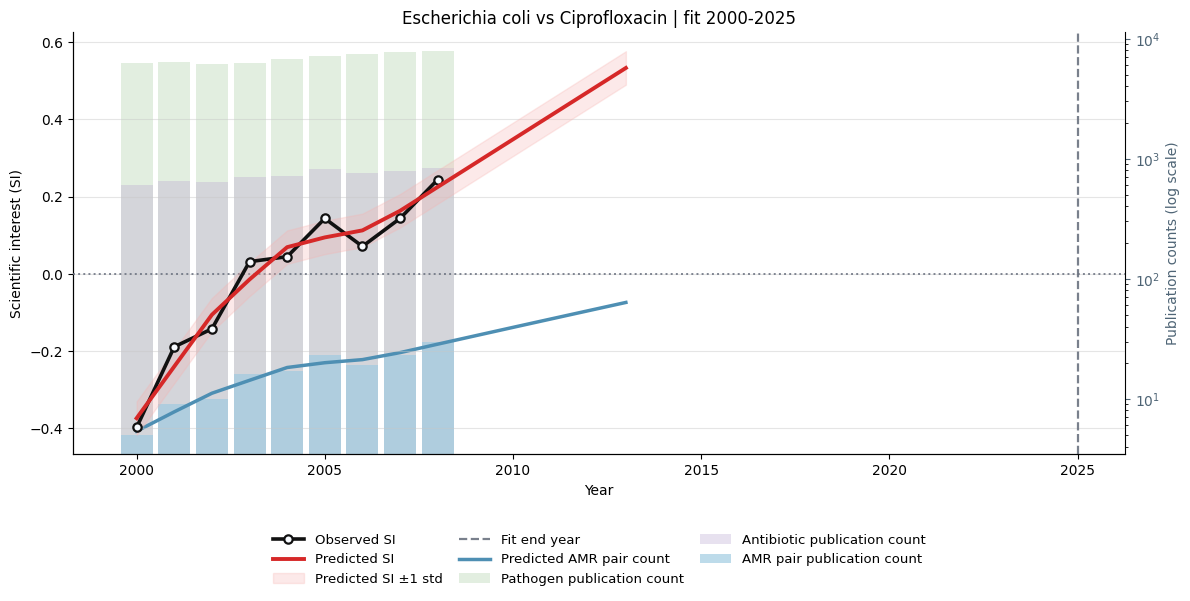

Saved 8 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


8

In [15]:
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
